
# 01. Exploratory Data Analysis (EDA)

## Cel notatnika

Celem tej analizy jest zbadanie zbioru danych  Default of Credit Card Clients.

Analiza będzie skupiona na:
- Zrozumieniu struktury zbioru oraz jego zawartości,
- Sprawdzenie zależności między zmiennymi a finalną predykcją
- Sprawdzenie jakości danych,
- Poszukanie wzoru który może być kluczowy do przewidywania

Efekty tej części pracy będą wsparciem do późniejszego preprocessingu danych, zbudowania modelu oraz kalibracji prawdopodobieństw.

## Zbiór

Source: UCI Machine Learning Repository – Default of Credit Card Clients

Analiza korzysta z zbioru utworzonego i wyeksportowanego w notatniku:`00_pozyskanie_danych.ipynb`.


In [ ]:
from pathlib import Path
import sys

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import StrMethodFormatter #do pokazywania pelnych wartosci zamiast notacji naukowych

current_path = Path.cwd().resolve()

PROJECT_ROOT = next(
    (p for p in [current_path, *current_path.parents]
    if (p/"src").is_dir()),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Folder src not found.")

#Add project root to Python import paths
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0,str(PROJECT_ROOT))

print("Project catalog:", PROJECT_ROOT)

from src import data_loader as dl

CONFIG_PATH = PROJECT_ROOT / "config.yaml"
config = dl.load_config(CONFIG_PATH)

PROCESSED_DATA_PATH = dl.get_data_path(config, PROJECT_ROOT, "processed_dir")

print("Project root:", PROJECT_ROOT)
print("Processed data path:", PROCESSED_DATA_PATH)
print("Libraries imported successfully.")


Project catalog: C:\Users\justy\Documents\Studia podyplomowe\Praca dyplomowa\credit-default-calibration
Project root: C:\Users\justy\Documents\Studia podyplomowe\Praca dyplomowa\credit-default-calibration
Processed data path: C:\Users\justy\Documents\Studia podyplomowe\Praca dyplomowa\credit-default-calibration\data\processed
Libraries imported successfully.


In [7]:
DATA_FILE = PROCESSED_DATA_PATH / "credit_default_data.csv"

if not DATA_FILE.exists():
    raise FileNotFoundError(f"Data file {DATA_FILE} not found. Please run the data processing script first.")

credits_df = pd.read_csv(DATA_FILE)

print("Dataset loaded successfully.")
print("Dataset shape:", credits_df.shape)

display(credits_df.head())
credits_df.info()

Dataset loaded successfully.
Dataset shape: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_A

In [18]:
TARGET_COLUMN = credits_df.columns[-1]  

target_counts = credits_df[TARGET_COLUMN].value_counts().sort_index()
target_percentages = credits_df[TARGET_COLUMN].value_counts(normalize=True) * 100

target_distribution_df = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentages
})

display(target_distribution_df)

,Count,Percentage
default payment next month,,
0,23364,77.88
1,6636,22.12


C:\Users\justy\AppData\Local\Temp\ipykernel_13072\1731514815.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=credits_df, x=TARGET_COLUMN, palette="Set2")


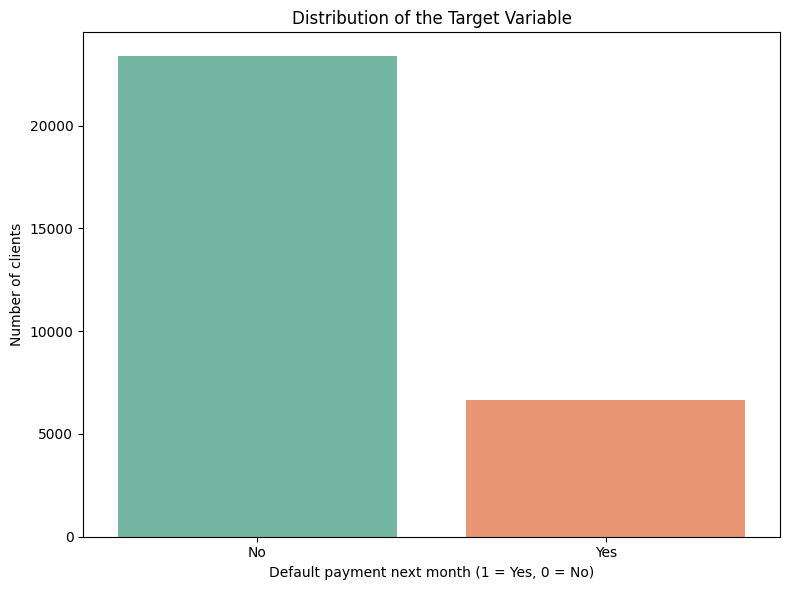

In [20]:
plt.figure(figsize=(8, 6))
sns.countplot(data=credits_df, x=TARGET_COLUMN, palette="Set2")

plt.title(f"Distribution of the Target Variable")
plt.xlabel("Default payment next month (1 = Yes, 0 = No)") #1 opózniona
plt.ylabel("Number of clients")
plt.xticks(ticks=[0, 1], labels=["No", "Yes"])
plt.tight_layout()
plt.show()


### 1. Dystrybucja zmiennej prognozowej

Balans zmiennej celowej:
- klasa 0 (terminowa płatność): 23 364 obserwacje (78%)
- klasa 1 (opóźnienie w płatności): 6 636 obserwacji (22%)

Klasa większościowa liczy w przybliżeniu 3,5 raza więcej obserwacji niż klasa mniejszościowa. 
Ta nierównowaga klas oznacza, że sama dokładność (accuracy) może być myląca przy ocenie modeli klasyfikacyjnych. Dalsza ewaluacja modelu powinna uwzględniać metryki biorące pod uwagę klasę mniejszościową, takie jak czułość (recall), precyzja (precision), miara F1 (F1-score) oraz ROC-AUC. 
Na tym etapie nie zastosowano żadnych technik ponownego próbkowania (resampling).


## 2. Statystyki opisowe

W tej sekcji przeanalizowano statystyki opisowe zmiennych numerycznych, aby zrozumieć ich rozkłady, miary tendencji centralnej, zmienność oraz zakresy.
Analiza ta pomoże zidentyfikować wartości nietypowe oraz potencjalne problemy z jakością danych, które mogą wymagać dalszego zbadania na etapie wstępnego przetwarzania (preprocessing).

In [21]:
descriptive_stats = credits_df.describe().T
display(descriptive_stats)

,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.500000,8660.398374,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0


### Wstępne obserwacje
- Każda zmienna ma 30 tys obserwacji co oznacza brak wartosci NaN
- ID - identyfikator klienta - nie jest cechą opisującą
- SEX (1-M, 2-F), EDUCATION i MARRIAGE - zmienne kategoryczne - zidentyfikowano wartości spoza zakresu opisanego w dokumantacji zbioru
- AGE - Średnia jest nieco wyższa od mediany, co może wskazywać na prawostronną asymetrię rozkładu
- PAY_0–PAY_6 – statusy spłat - zidentyfikowano wartości spoza zakresu opisanego w dokumantacji zbioru (-2)
- BILL_AMT i PAY_AMT – kwoty rachunków i spłat - zidentyfikowano ujemne wartości rachunków, bardzo wysokie maxy, 

ujemne wartości rachunków oraz bardzo wysokie maxy wymagają głębszej analizy

In [23]:
categorical_columns = [
    "SEX",
    "EDUCATION",
    "MARRIAGE",
    "PAY_0",
    "PAY_2",
    "PAY_3",
    "PAY_4",
    "PAY_5",
    "PAY_6"
]

for c in categorical_columns:
    print(f"\n{'-' * 50}")
    print(f"Variable: {c}")
    print(f"{'-' * 50}")

    counts = credits_df[c].value_counts(dropna=False).sort_index()
    percentages = credits_df[c].value_counts(normalize=True, dropna=False).sort_index() * 100

    distribution_df = pd.DataFrame({
        "Count": counts,
        "Percentage": percentages
    })
    display(distribution_df)


--------------------------------------------------
Variable: SEX
--------------------------------------------------


,Count,Percentage
SEX,,
1,11888,39.626667
2,18112,60.373333



--------------------------------------------------
Variable: EDUCATION
--------------------------------------------------


,Count,Percentage
EDUCATION,,
0,14,0.046667
1,10585,35.283333
2,14030,46.766667
3,4917,16.390000
4,123,0.410000
5,280,0.933333
6,51,0.170000



--------------------------------------------------
Variable: MARRIAGE
--------------------------------------------------


,Count,Percentage
MARRIAGE,,
0,54,0.180000
1,13659,45.530000
2,15964,53.213333
3,323,1.076667


... (8 outputs left out)


--------------------------------------------------
Variable: PAY_5
--------------------------------------------------


,Count,Percentage
PAY_5,,
-2,4546,15.153333
-1,5539,18.463333
0,16947,56.490000
2,2626,8.753333
3,178,0.593333
4,84,0.280000
5,17,0.056667
6,4,0.013333
7,58,0.193333



--------------------------------------------------
Variable: PAY_6
--------------------------------------------------


,Count,Percentage
PAY_6,,
-2,4895,16.316667
-1,5740,19.133333
0,16286,54.286667
2,2766,9.220000
3,184,0.613333
4,49,0.163333
5,13,0.043333
6,19,0.063333
7,46,0.153333



### Zmienne kategoryczne a status spłaty

Zmienne kategoryczne wykazują zróżnicowany stopień niezrównoważenia klas (kategorii).
• SEX (płeć): kategoria 2 stanowi około 60,4% obserwacji.
• EDUCATION (wykształcenie): kategorie 1 i 2 odpowiadają za około 82,1% obserwacji. Pojawiają się również dodatkowe kody 0, 5 i 6, które wymagają dalszego zbadania.
• MARRIAGE (stan cywilny): kategorie 1 i 2 obejmują około 98,7% obserwacji. Kody 0 i 3 występują stosunkowo rzadko.
• PAY_0–PAY_6: status spłaty oznaczony jako 0 jest najczęściej występującą kategorią we wszystkich sześciu zmiennych, a tuż za nim plasują się wartości -1 oraz -2.

## 3. Rozkład zmiennych numerycznych
W tej sekcji przedstawiono analizę rozkładów ciągłych zmiennych numerycznych. Za pomocą histogramów zbadano kształt tych rozkładów, zidentyfikowano skośność oraz określono koncentrację wartości. Pionowe linie oznaczają średnią oraz medianę, co ułatwia interpretację poszczególnych rozkładów.

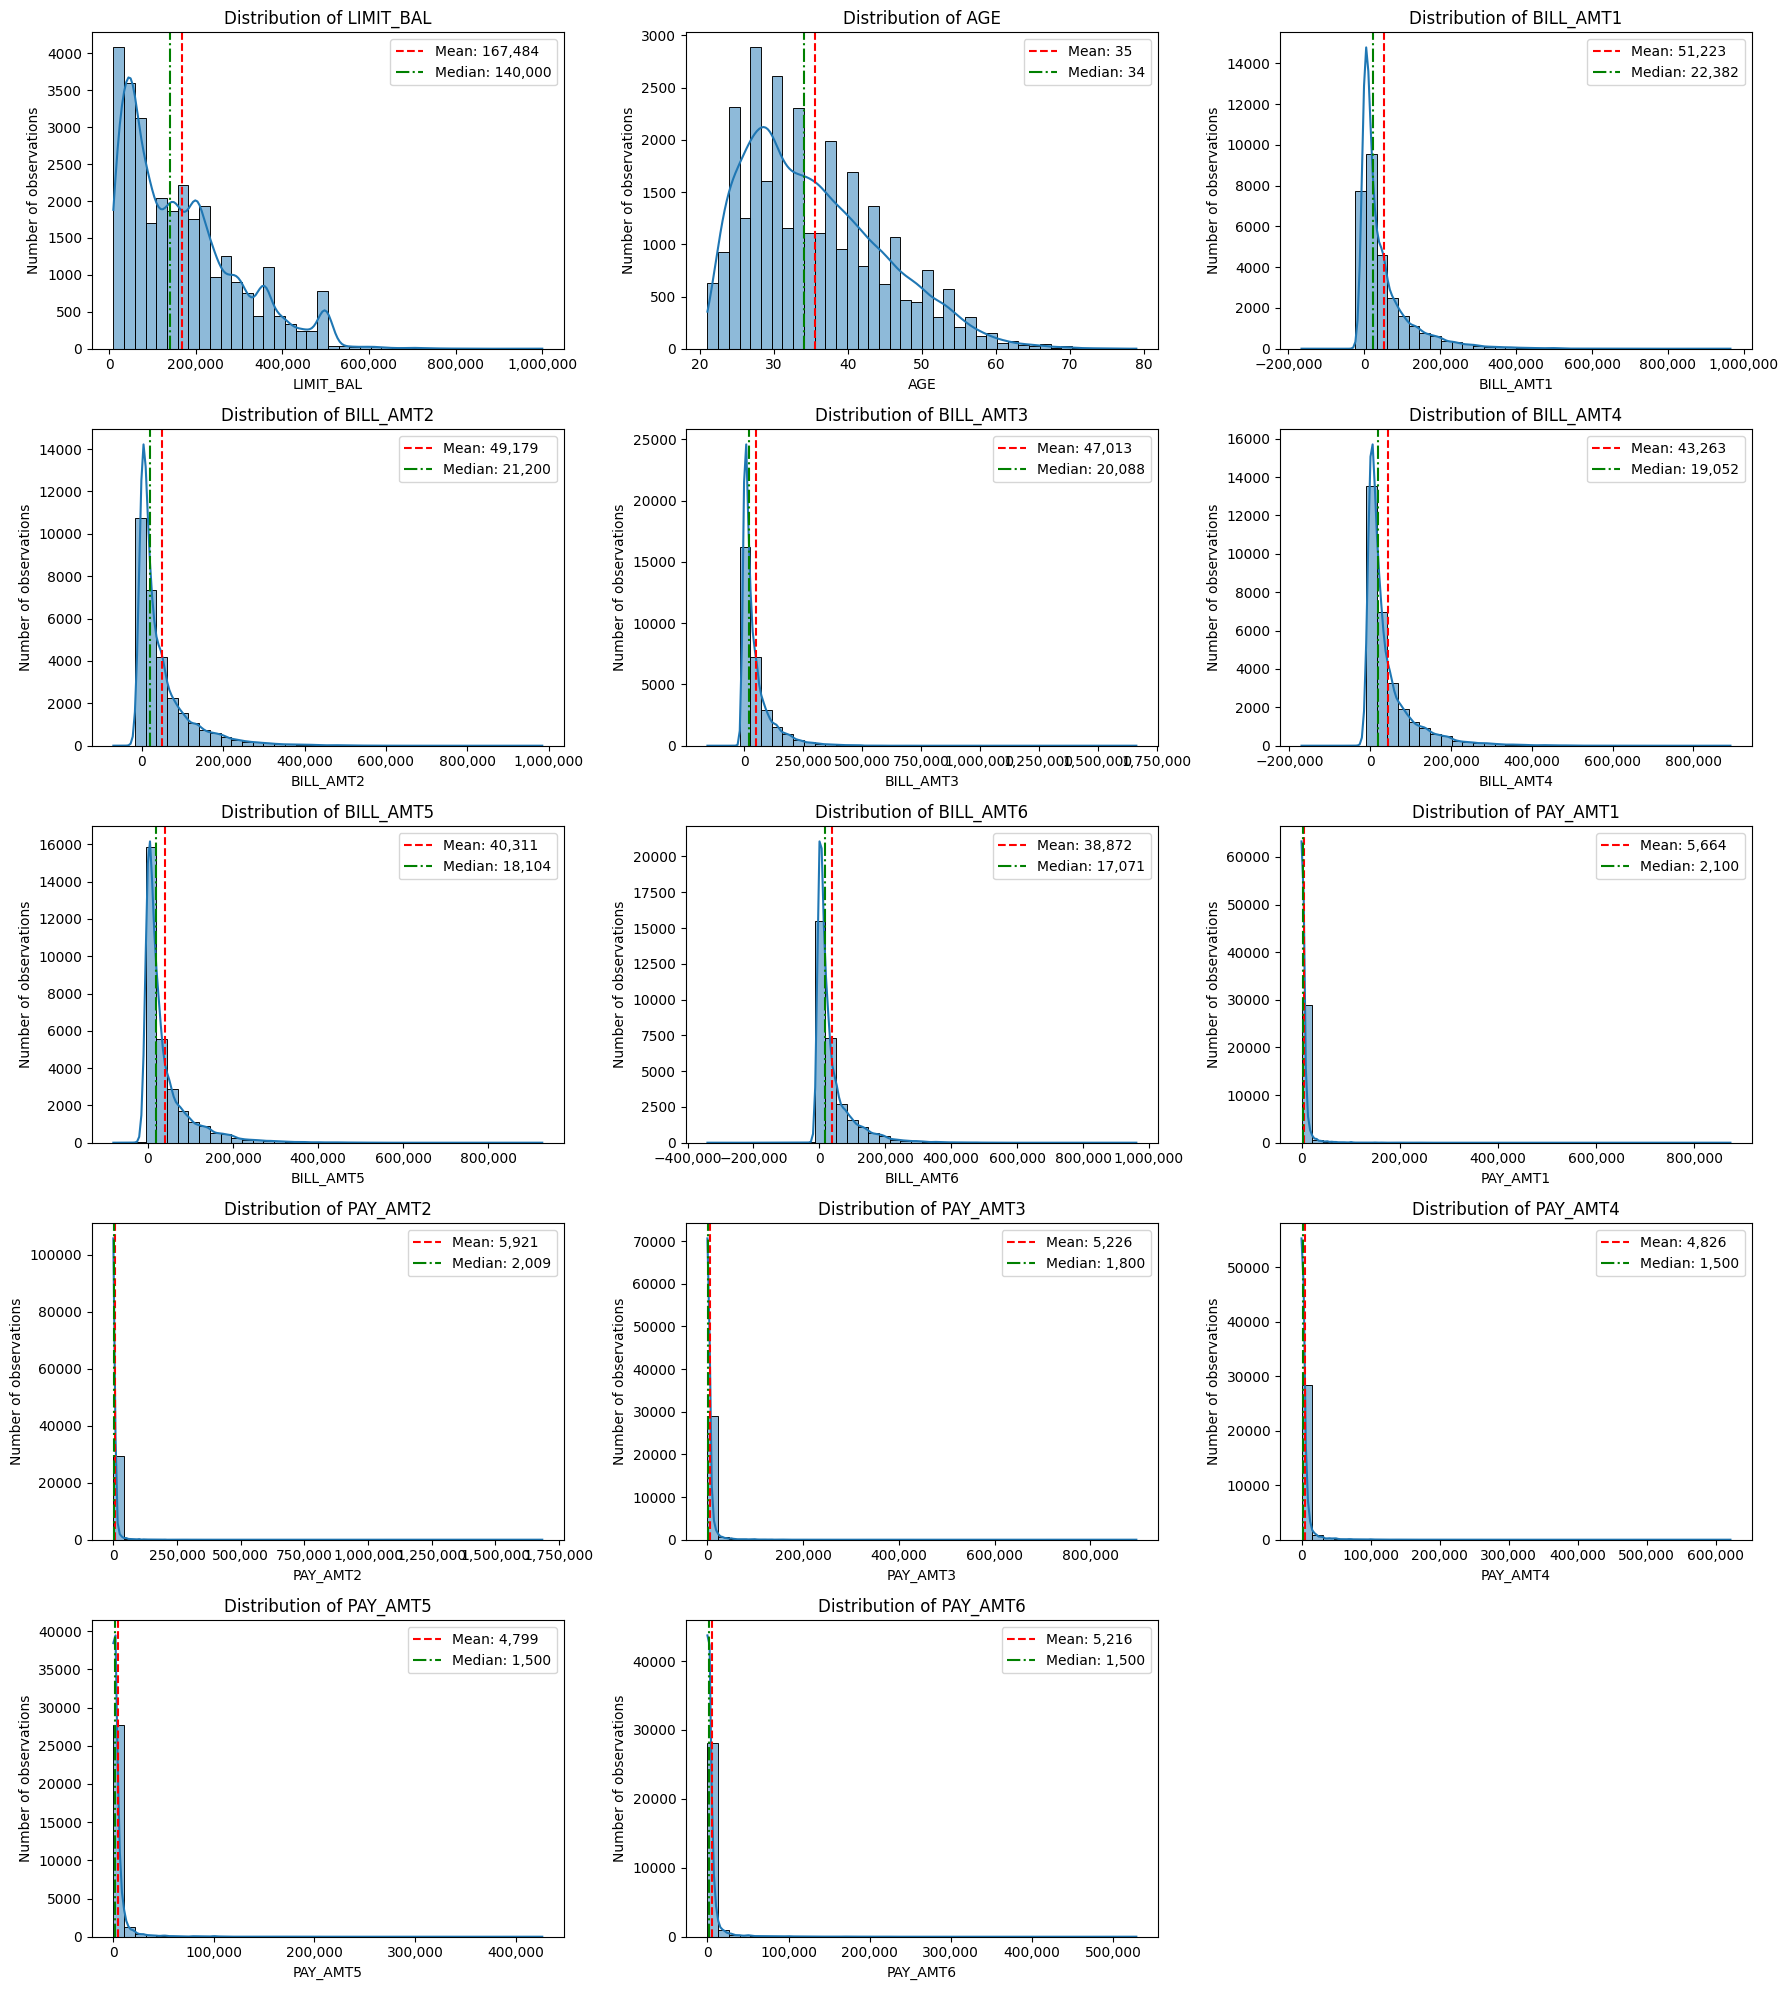

In [28]:
numerical_columns = [
    "LIMIT_BAL",
    "AGE",
    "BILL_AMT1",
    "BILL_AMT2",
    "BILL_AMT3",
    "BILL_AMT4",
    "BILL_AMT5",
    "BILL_AMT6",
    "PAY_AMT1",
    "PAY_AMT2",
    "PAY_AMT3",
    "PAY_AMT4",
    "PAY_AMT5",
    "PAY_AMT6"
]

n_cols = 3
n_rows = int(np.ceil(len(numerical_columns) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(18, 4 * n_rows)
)

# Convert the axes array into a one-dimensional array
# so that we can iterate over all subplots.
axes = axes.flatten()

for i, column in enumerate(numerical_columns):

    ax = axes[i]

    # Calculate mean and median for the current variable.
    mean_value = credits_df[column].mean()
    median_value = credits_df[column].median()

    # Draw the histogram.
    sns.histplot(
        data=credits_df,
        x=column,
        bins=40,
        kde=True,
        ax=ax
    )

    # Add vertical lines representing the mean and median.
    ax.axvline(
        mean_value,
        color="red",
        linestyle="--",
        label=f"Mean: {mean_value:,.0f}"
    )

    ax.axvline(
        median_value,
        color="green",
        linestyle="-.",
        label=f"Median: {median_value:,.0f}"
    )
    ax.xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))  # Format x-axis labels with commas
    ax.set_title(f"Distribution of {column}")
    ax.set_ylabel("Number of observations")
    ax.legend()

# Hide any unused subplot axes.
for j in range(len(numerical_columns), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()


### Analiza wartości odstających

Wykresy pudełkowe (tzw. boxploty) służą do identyfikacji potencjalnych wartości odstających w zmiennych liczbowych. Pudełko reprezentuje rozstęp międzykwartylowy (IQR), a mediana jest przedstawiona jako linia wewnątrz pudełka. Wąsy sięgają do najbardziej skrajnych obserwacji mieszczących się w granicach 1,5 raza IQR od kwartyli. Obserwacje leżące poza wąsami są oznaczane jako potencjalne wartości odstające. 
Nie są one automatycznie uznawane za błędne i na tym etapie nie będą usuwane.


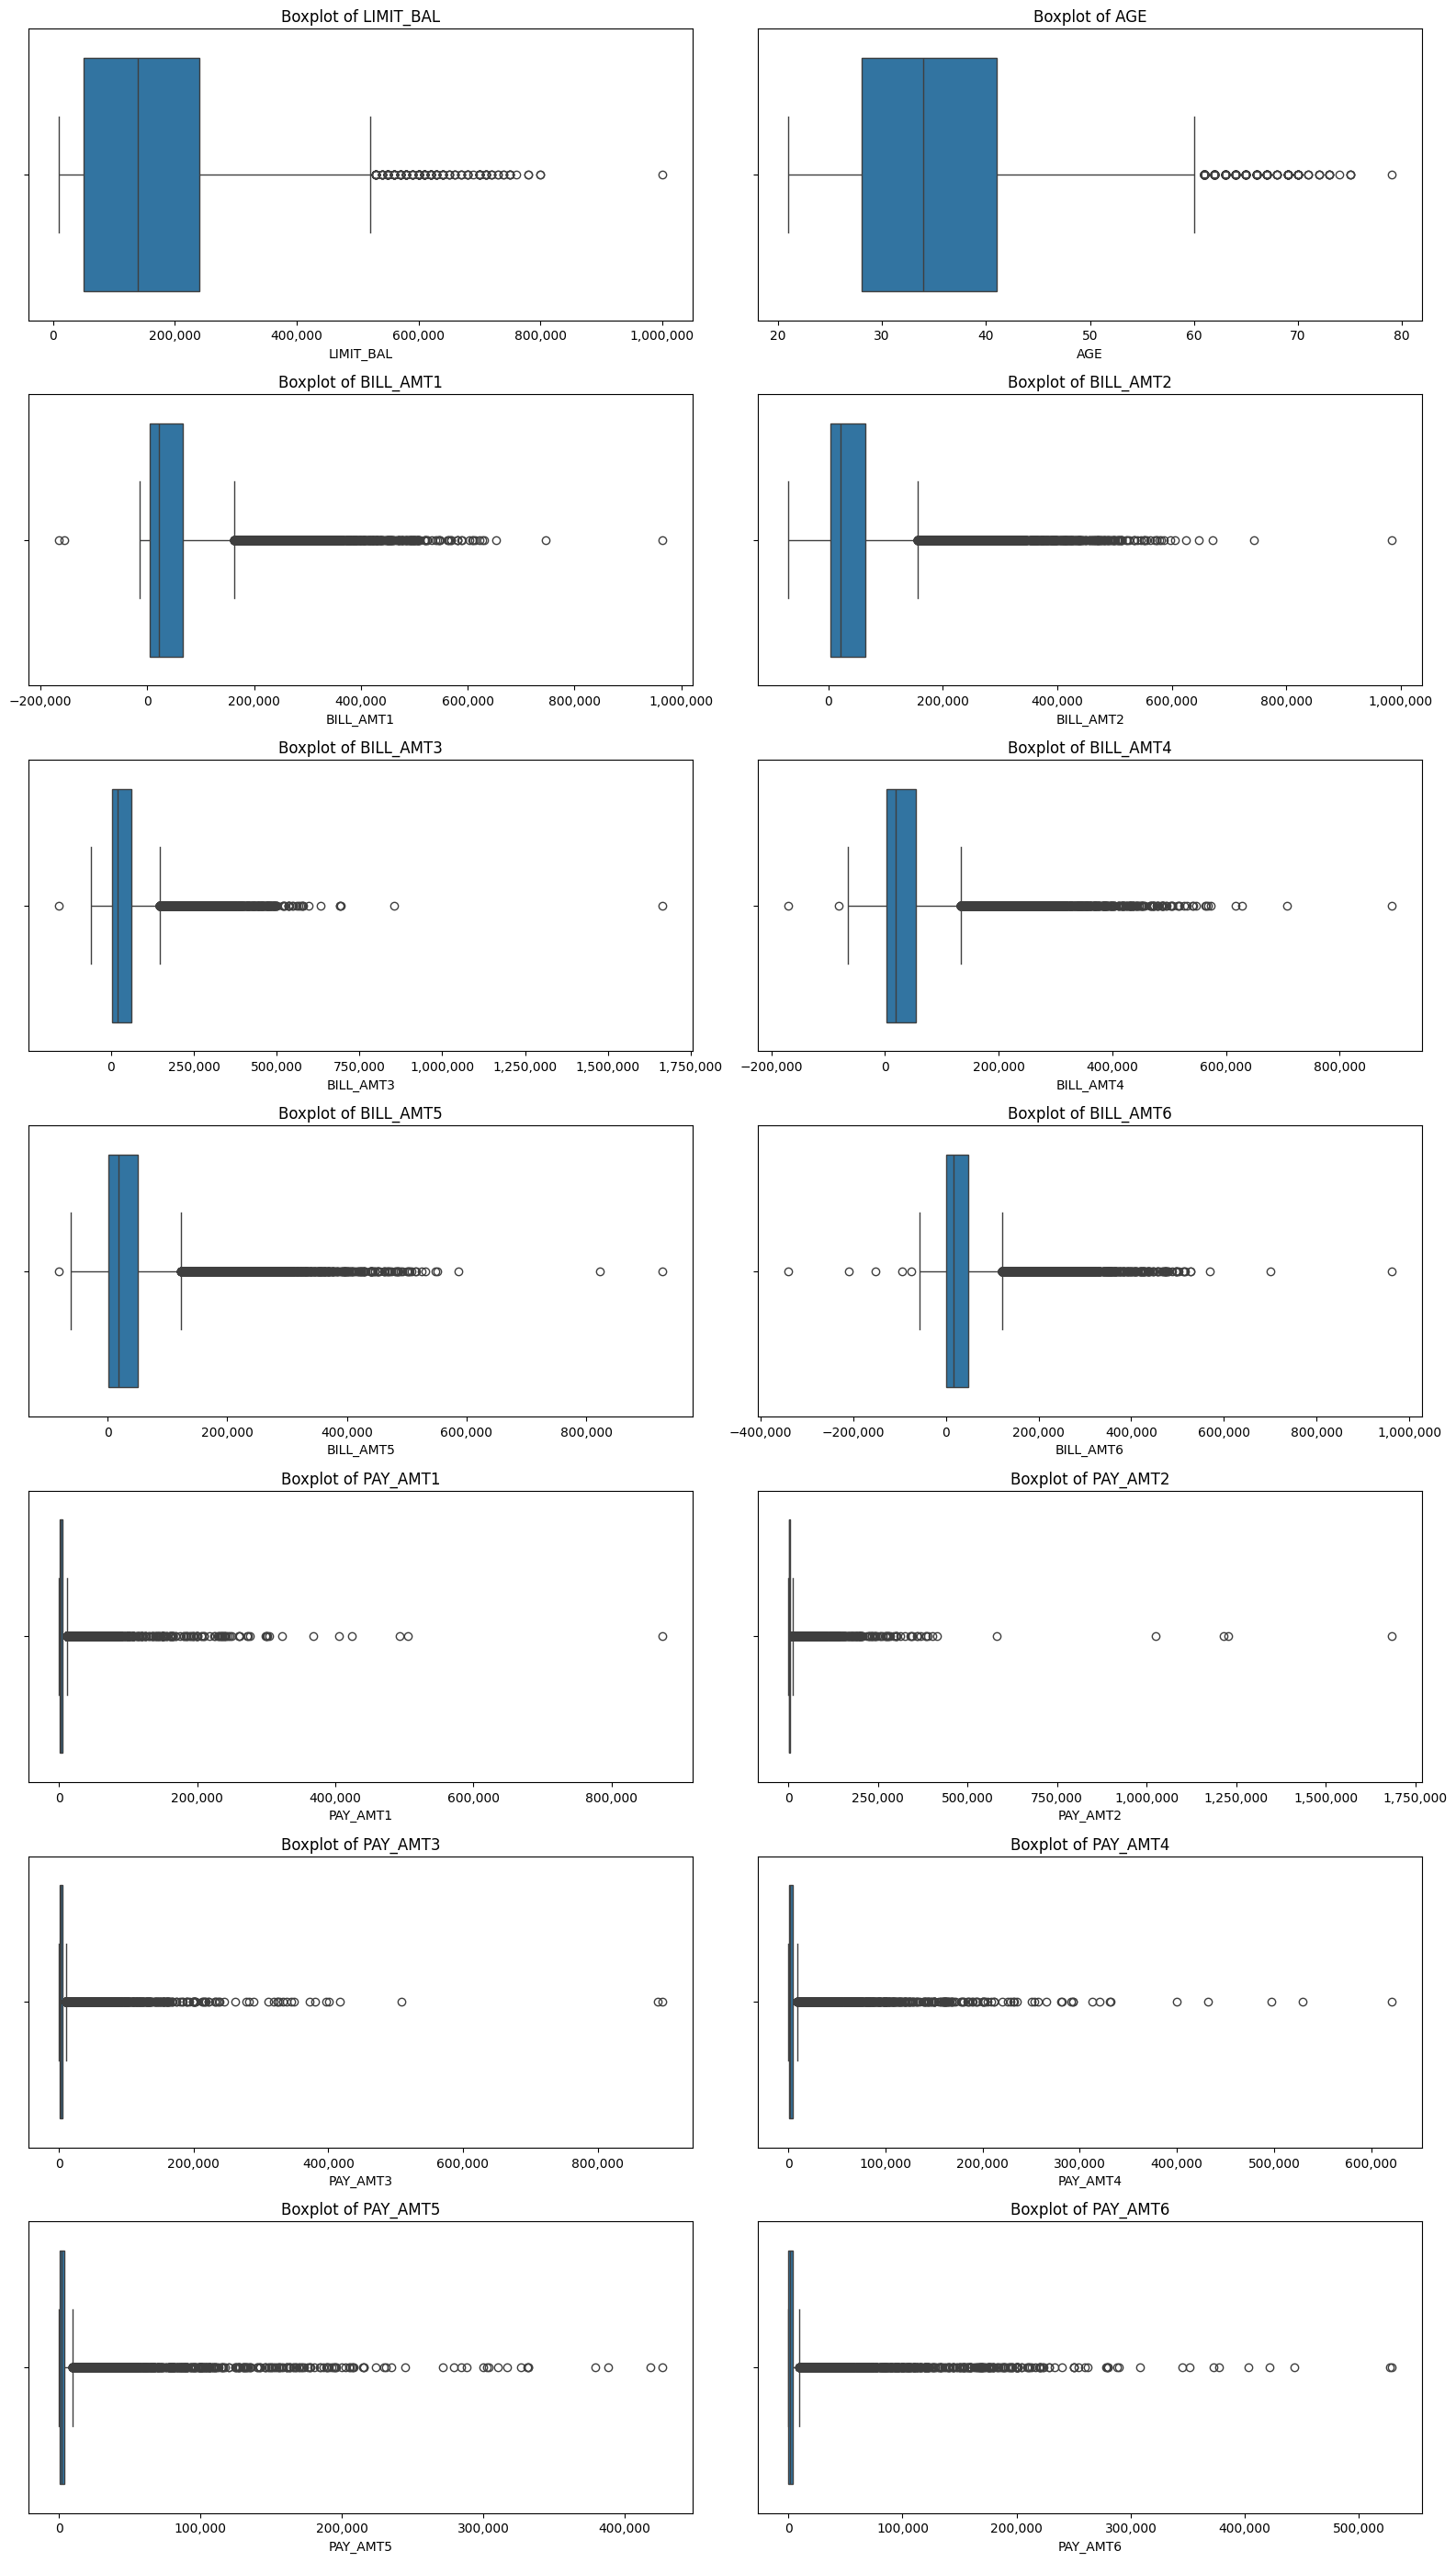

In [29]:

# Create boxplots for all selected numerical variables.
# Each variable gets its own subplot to make the distributions easier to read.

n_cols = 2
n_rows = int(np.ceil(len(numerical_columns) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(16, 4 * n_rows)
)

axes = axes.flatten()

for i, column in enumerate(numerical_columns):

    ax = axes[i]

    # Draw a boxplot for the current variable.
    sns.boxplot(
        data=credits_df,
        x=column,
        ax=ax
    )
    ax.xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))  # Format x-axis labels with commas
    ax.set_title(f"Boxplot of {column}")
    ax.set_xlabel(column)

# Hide unused subplot axes.
for j in range(len(numerical_columns), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()


## 5. Analiza korelacji

W tej sekcji zbadano zależności liniowe między zmiennymi numerycznymi przy użyciu współczynnika korelacji Pearsona.
Macierz korelacji została przedstawiona w formie mapy cieplnej (heatmapy), aby zidentyfikować silnie skorelowane predyktory oraz potencjalne związki ze zmienną docelową.
Korelacja nie oznacza przyczynowości.


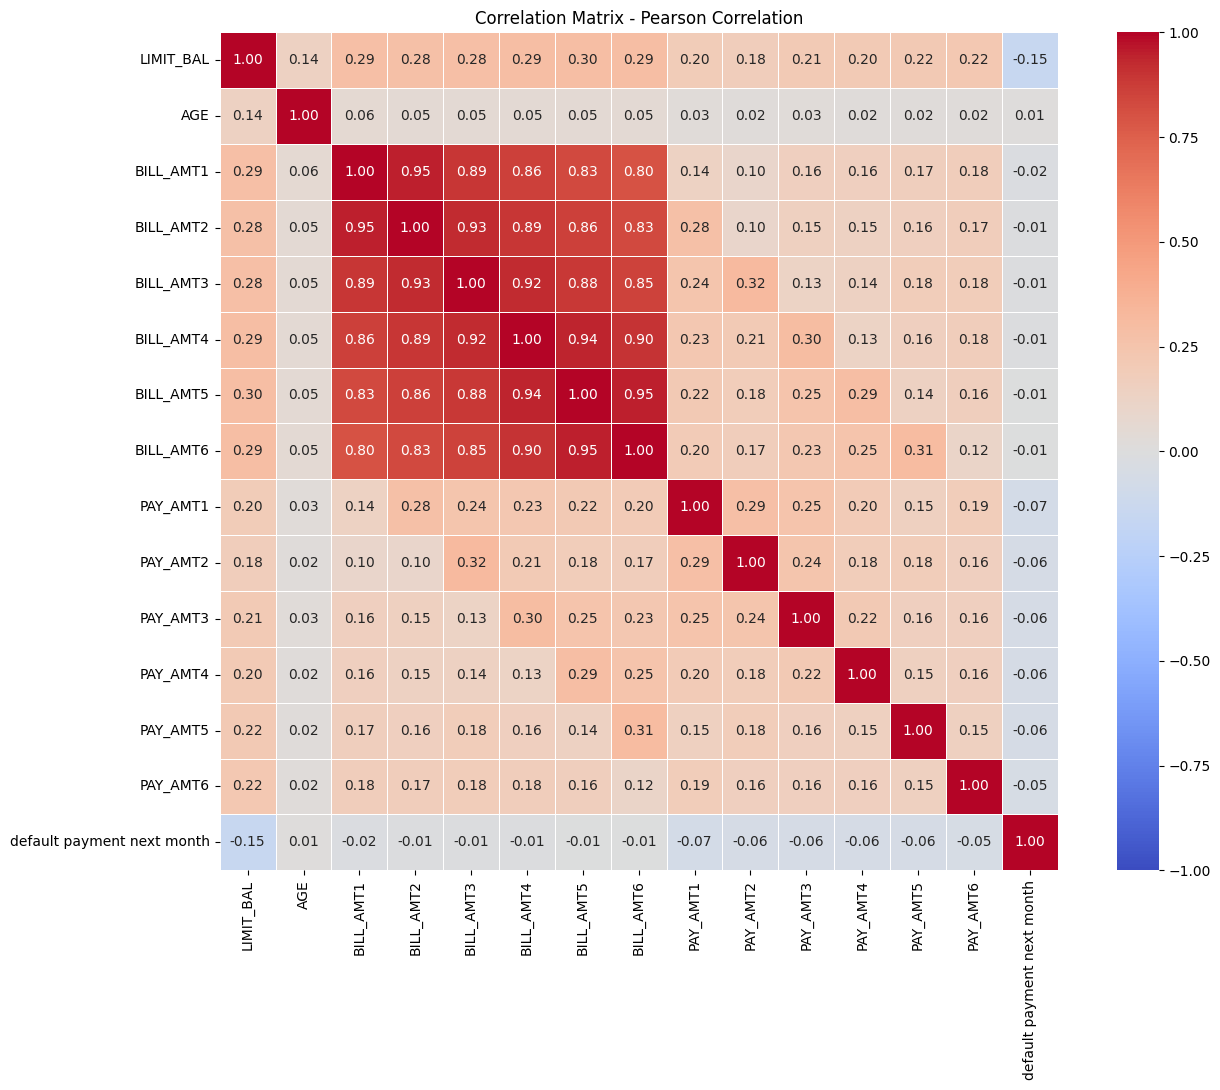

In [32]:

# Select continuous numerical variables and the target variable.
correlation_columns = numerical_columns + [TARGET_COLUMN]

correlation_matrix = credits_df[correlation_columns].corr(method="pearson")

# Display the correlation matrix as a heatmap.
plt.figure(figsize=(14, 11))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5
)

plt.title("Correlation Matrix - Pearson Correlation")
plt.tight_layout()
plt.show()


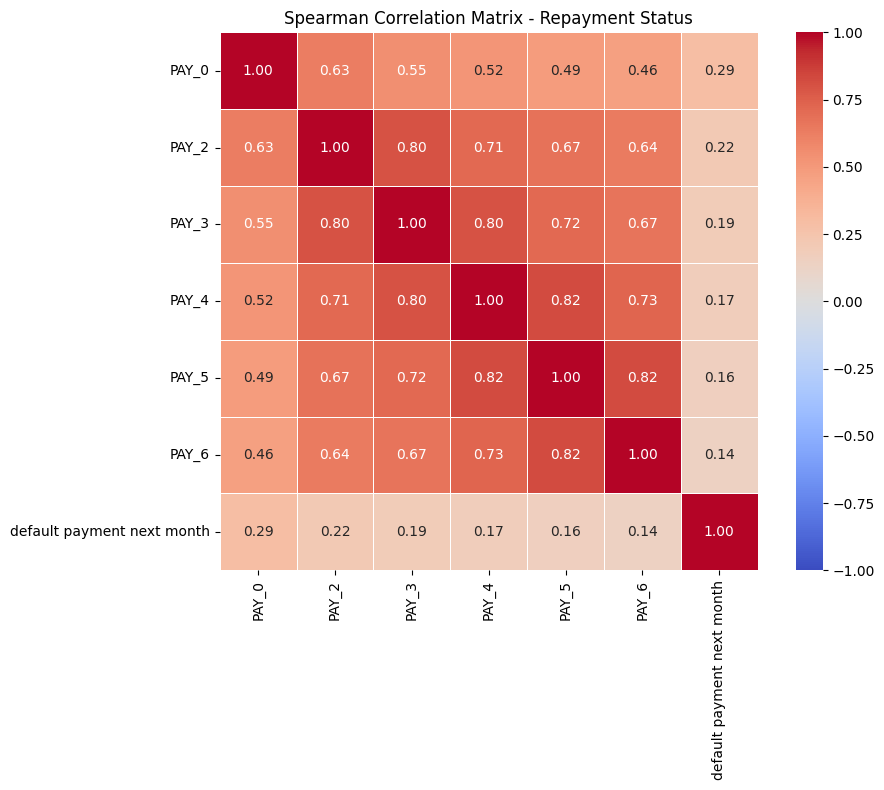

In [33]:

# Select repayment status variables and the target variable.
pay_columns = [
    "PAY_0",
    "PAY_2",
    "PAY_3",
    "PAY_4",
    "PAY_5",
    "PAY_6",
    TARGET_COLUMN
]

# Calculate Spearman rank correlations.
pay_correlation_matrix = credits_df[pay_columns].corr(method="spearman")

# Visualize the correlation matrix.
plt.figure(figsize=(10, 8))

sns.heatmap(
    pay_correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5
)

plt.title("Spearman Correlation Matrix - Repayment Status")
plt.tight_layout()
plt.show()
